# SQL Loan Application Portfolio Analysis

## Project Overview

This project used SQL and Python to analyze historical loan applicaiton data. The goal was to try to find patterns in loan approval outcomes, applicant characteristics, loan amounts, and interest rates.

Tools used: SQL, SQLite, Python, pandas, Matplotlib, and Google Colab

How can we translate loan application data into descriptive insights that can support further investigation of historical lending decisions?


In [2]:
import pandas as pd
import sqlite3
from IPython.display import display
df=pd.read_csv("loan_data.csv")

conn=sqlite3.connect(":memory:")

df.to_sql("loan_applications", conn, if_exists="replace", index=False)

print("Dataset loaded successfully!")
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print("SQL table created: loan_applications")

display(df.head())

Dataset loaded successfully!
Rows: 45,000
Columns: 14
SQL table created: loan_applications


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [4]:
def run_query(query):
    result = pd.read_sql_query(query, conn)
    display(result)
    return result

In [5]:
run_query("""
SELECT
    name AS column_name,
    type AS data_type
FROM pragma_table_info('loan_applications');
""")

,column_name,data_type
0,person_age,REAL
1,person_gender,TEXT
2,person_education,TEXT
3,person_income,REAL
4,person_emp_exp,INTEGER
5,person_home_ownership,TEXT
6,loan_amnt,REAL
7,loan_intent,TEXT
8,loan_int_rate,REAL
9,loan_percent_income,REAL


,column_name,data_type
0,person_age,REAL
1,person_gender,TEXT
2,person_education,TEXT
3,person_income,REAL
4,person_emp_exp,INTEGER
5,person_home_ownership,TEXT
6,loan_amnt,REAL
7,loan_intent,TEXT
8,loan_int_rate,REAL
9,loan_percent_income,REAL


In [6]:
run_query("""
SELECT COUNT(*) AS total_applications
FROM loan_applications;
""")

,total_applications
0,45000


,total_applications
0,45000


In [7]:
run_query("""
SELECT
    COUNT(*) AS total_applications,
    SUM(CASE WHEN loan_status = 1 THEN 1 ELSE 0 END)
        AS approved_applications,
    SUM(CASE WHEN loan_status = 0 THEN 1 ELSE 0 END)
        AS not_approved_applications,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications;
""")

,total_applications,approved_applications,not_approved_applications,approval_rate_pct
0,45000,10000,35000,22.22


,total_applications,approved_applications,not_approved_applications,approval_rate_pct
0,45000,10000,35000,22.22


In [8]:
run_query("""
SELECT
    loan_intent,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN loan_status = 1 THEN 1 ELSE 0 END)
        AS approved_applications,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
GROUP BY loan_intent
ORDER BY approval_rate_pct DESC;
""")

,loan_intent,total_applications,approved_applications,approval_rate_pct
0,DEBTCONSOLIDATION,7145,2163,30.27
1,MEDICAL,8548,2378,27.82
2,HOMEIMPROVEMENT,4783,1258,26.30
3,PERSONAL,7552,1521,20.14
4,EDUCATION,9153,1552,16.96
5,VENTURE,7819,1128,14.43


,loan_intent,total_applications,approved_applications,approval_rate_pct
0,DEBTCONSOLIDATION,7145,2163,30.27
1,MEDICAL,8548,2378,27.82
2,HOMEIMPROVEMENT,4783,1258,26.30
3,PERSONAL,7552,1521,20.14
4,EDUCATION,9153,1552,16.96
5,VENTURE,7819,1128,14.43


In [9]:
run_query("""
SELECT
    person_home_ownership,
    COUNT(*) AS total_applications,
    ROUND(AVG(person_income), 2) AS average_income,
    ROUND(AVG(loan_amnt), 2) AS average_loan_amount,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
GROUP BY person_home_ownership
ORDER BY approval_rate_pct DESC;
""")

,person_home_ownership,total_applications,average_income,average_loan_amount,approval_rate_pct
0,OTHER,117,91480.07,11282.32,33.33
1,RENT,23443,65001.14,8756.46,32.40
2,MORTGAGE,18489,101569.31,10716.83,11.60
3,OWN,2951,68423.41,8980.32,7.52


,person_home_ownership,total_applications,average_income,average_loan_amount,approval_rate_pct
0,OTHER,117,91480.07,11282.32,33.33
1,RENT,23443,65001.14,8756.46,32.40
2,MORTGAGE,18489,101569.31,10716.83,11.60
3,OWN,2951,68423.41,8980.32,7.52


In [10]:
run_query("""
SELECT
    CASE
        WHEN credit_score < 580 THEN 'Below 580'
        WHEN credit_score < 670 THEN '580-669'
        WHEN credit_score < 740 THEN '670-739'
        WHEN credit_score < 800 THEN '740-799'
        ELSE '800+'
    END AS credit_score_band,
    COUNT(*) AS total_applications,
    ROUND(AVG(credit_score), 1) AS average_credit_score,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
WHERE credit_score IS NOT NULL
GROUP BY credit_score_band
ORDER BY
    CASE credit_score_band
        WHEN 'Below 580' THEN 1
        WHEN '580-669' THEN 2
        WHEN '670-739' THEN 3
        WHEN '740-799' THEN 4
        WHEN '800+' THEN 5
    END;
""")

,credit_score_band,total_applications,average_credit_score,approval_rate_pct
0,Below 580,6901,546.0,22.30
1,580-669,26806,630.6,22.48
2,670-739,11196,689.9,21.55
3,740-799,94,749.8,22.34
4,800+,3,820.7,0.00


,credit_score_band,total_applications,average_credit_score,approval_rate_pct
0,Below 580,6901,546.0,22.30
1,580-669,26806,630.6,22.48
2,670-739,11196,689.9,21.55
3,740-799,94,749.8,22.34
4,800+,3,820.7,0.00


In [11]:
run_query("""
SELECT
    CASE
        WHEN loan_percent_income < 0.10 THEN 'Below 10%'
        WHEN loan_percent_income < 0.20 THEN '10%-19.9%'
        WHEN loan_percent_income < 0.30 THEN '20%-29.9%'
        WHEN loan_percent_income < 0.40 THEN '30%-39.9%'
        ELSE '40%+'
    END AS loan_to_income_band,
    COUNT(*) AS total_applications,
    ROUND(AVG(loan_percent_income) * 100, 2)
        AS average_loan_to_income_pct,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
WHERE loan_percent_income IS NOT NULL
GROUP BY loan_to_income_band
ORDER BY
    CASE loan_to_income_band
        WHEN 'Below 10%' THEN 1
        WHEN '10%-19.9%' THEN 2
        WHEN '20%-29.9%' THEN 3
        WHEN '30%-39.9%' THEN 4
        ELSE 5
    END;
""")

,loan_to_income_band,total_applications,average_loan_to_income_pct,approval_rate_pct
0,Below 10%,16445,5.90,11.82
1,10%-19.9%,18149,13.92,16.72
2,20%-29.9%,7606,23.69,39.28
3,30%-39.9%,2286,33.33,72.09
4,40%+,514,44.11,75.10


,loan_to_income_band,total_applications,average_loan_to_income_pct,approval_rate_pct
0,Below 10%,16445,5.90,11.82
1,10%-19.9%,18149,13.92,16.72
2,20%-29.9%,7606,23.69,39.28
3,30%-39.9%,2286,33.33,72.09
4,40%+,514,44.11,75.10


In [12]:
run_query("""
SELECT
    loan_status,
    CASE
        WHEN loan_status = 1 THEN 'Approved'
        ELSE 'Not Approved'
    END AS approval_outcome,
    COUNT(*) AS total_applications,
    ROUND(AVG(person_income), 2) AS average_income,
    ROUND(AVG(loan_amnt), 2) AS average_loan_amount,
    ROUND(AVG(loan_percent_income) * 100, 2)
        AS average_loan_to_income_pct,
    ROUND(AVG(credit_score), 1) AS average_credit_score,
    ROUND(AVG(cb_person_cred_hist_length), 2)
        AS average_credit_history_years
FROM loan_applications
GROUP BY loan_status
ORDER BY loan_status DESC;
""")

,loan_status,approval_outcome,total_applications,average_income,average_loan_amount,average_loan_to_income_pct,average_credit_score,average_credit_history_years
0,1,Approved,10000,59886.10,10855.69,20.25,631.9,5.76
1,0,Not Approved,35000,86157.04,9219.58,12.18,632.8,5.90


,loan_status,approval_outcome,total_applications,average_income,average_loan_amount,average_loan_to_income_pct,average_credit_score,average_credit_history_years
0,1,Approved,10000,59886.10,10855.69,20.25,631.9,5.76
1,0,Not Approved,35000,86157.04,9219.58,12.18,632.8,5.90


In [13]:
run_query("""
SELECT
    previous_loan_defaults_on_file,
    COUNT(*) AS total_applications,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
GROUP BY previous_loan_defaults_on_file
ORDER BY approval_rate_pct DESC;
""")

,previous_loan_defaults_on_file,total_applications,approval_rate_pct
0,No,22142,45.16
1,Yes,22858,0.00


,previous_loan_defaults_on_file,total_applications,approval_rate_pct
0,No,22142,45.16
1,Yes,22858,0.00


In [14]:
run_query("""
SELECT
    CASE
        WHEN person_emp_exp < 2 THEN 'Less than 2 years'
        WHEN person_emp_exp < 5 THEN '2-4 years'
        WHEN person_emp_exp < 10 THEN '5-9 years'
        ELSE '10+ years'
    END AS employment_experience_band,
    COUNT(*) AS total_applications,
    ROUND(AVG(person_income), 2) AS average_income,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
WHERE person_emp_exp IS NOT NULL
GROUP BY employment_experience_band
ORDER BY
    CASE employment_experience_band
        WHEN 'Less than 2 years' THEN 1
        WHEN '2-4 years' THEN 2
        WHEN '5-9 years' THEN 3
        ELSE 4
    END;
""")

,employment_experience_band,total_applications,average_income,approval_rate_pct
0,Less than 2 years,13627,69970.51,23.84
1,2-4 years,11548,77238.62,21.93
2,5-9 years,11386,84644.80,21.55
3,10+ years,8439,95408.46,20.93


,employment_experience_band,total_applications,average_income,approval_rate_pct
0,Less than 2 years,13627,69970.51,23.84
1,2-4 years,11548,77238.62,21.93
2,5-9 years,11386,84644.80,21.55
3,10+ years,8439,95408.46,20.93


In [15]:
missing_values = pd.DataFrame({
    "column_name": df.columns,
    "missing_count": df.isna().sum().values,
    "missing_pct": (
        df.isna().mean().values * 100
    ).round(2)
})

display(
    missing_values.sort_values(
        "missing_pct",
        ascending=False
    ).reset_index(drop=True)
)

,column_name,missing_count,missing_pct
0,person_age,0,0.0
1,person_gender,0,0.0
2,person_education,0,0.0
3,person_income,0,0.0
4,person_emp_exp,0,0.0
5,person_home_ownership,0,0.0
6,loan_amnt,0,0.0
7,loan_intent,0,0.0
8,loan_int_rate,0,0.0
9,loan_percent_income,0,0.0


In [16]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

Exact duplicate rows: 0


In [17]:
run_query("""
SELECT
    CASE
        WHEN loan_status = 1 THEN 'Approved'
        ELSE 'Not Approved'
    END AS approval_outcome,
    COUNT(loan_int_rate) AS records_with_interest_rate,
    ROUND(AVG(loan_int_rate), 2) AS average_interest_rate,
    ROUND(MIN(loan_int_rate), 2) AS minimum_interest_rate,
    ROUND(MAX(loan_int_rate), 2) AS maximum_interest_rate
FROM loan_applications
GROUP BY loan_status
ORDER BY loan_status DESC;
""")

,approval_outcome,records_with_interest_rate,average_interest_rate,minimum_interest_rate,maximum_interest_rate
0,Approved,10000,12.86,5.42,20.0
1,Not Approved,35000,10.48,5.42,20.0


,approval_outcome,records_with_interest_rate,average_interest_rate,minimum_interest_rate,maximum_interest_rate
0,Approved,10000,12.86,5.42,20.0
1,Not Approved,35000,10.48,5.42,20.0


,loan_intent,approval_rate_pct
0,DEBTCONSOLIDATION,30.27
1,MEDICAL,27.82
2,HOMEIMPROVEMENT,26.30
3,PERSONAL,20.14
4,EDUCATION,16.96
5,VENTURE,14.43


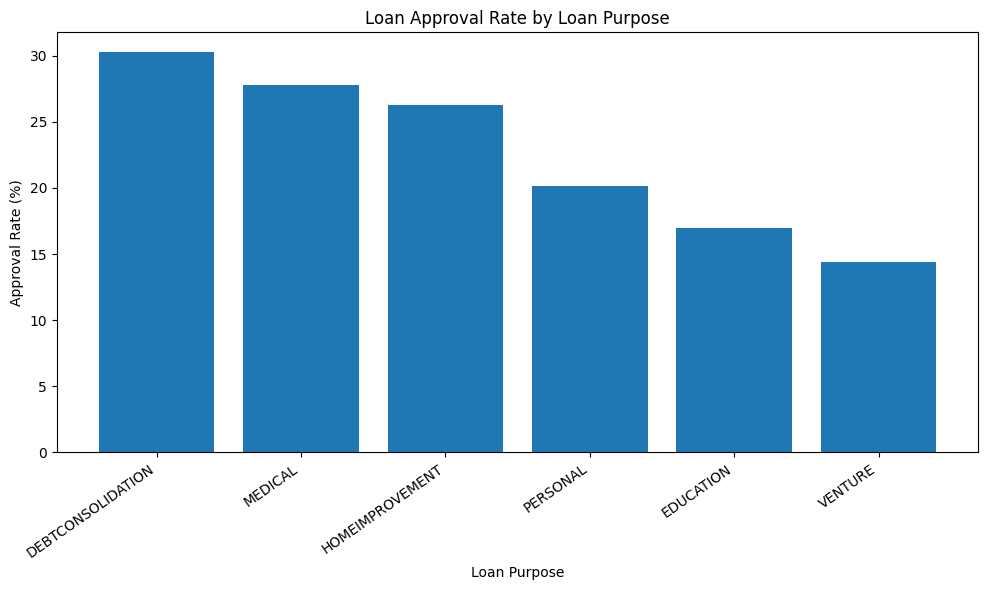

In [18]:
import matplotlib.pyplot as plt

approval_by_intent = pd.read_sql_query("""
SELECT
    loan_intent,
    ROUND(
        100.0 * AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END),
        2
    ) AS approval_rate_pct
FROM loan_applications
GROUP BY loan_intent
ORDER BY approval_rate_pct DESC;
""", conn)

display(approval_by_intent)

plt.figure(figsize=(10, 6))
plt.bar(
    approval_by_intent["loan_intent"],
    approval_by_intent["approval_rate_pct"]
)
plt.title("Loan Approval Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,credit_score_band,approval_rate_pct
0,Below 580,22.301116
1,580-669,22.483772
2,670-739,21.552340
3,740-799,22.340426
4,800+,0.000000


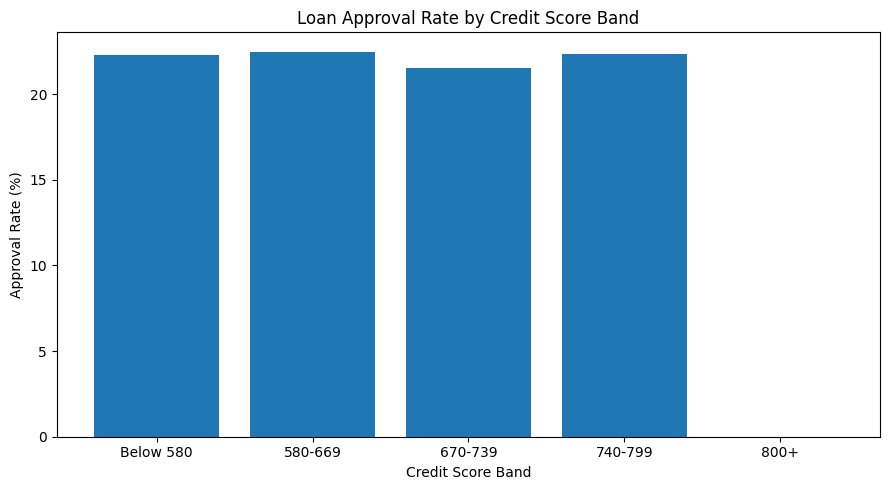

In [19]:
credit_approval = pd.read_sql_query("""
SELECT
    CASE
        WHEN credit_score < 580 THEN 'Below 580'
        WHEN credit_score < 670 THEN '580-669'
        WHEN credit_score < 740 THEN '670-739'
        WHEN credit_score < 800 THEN '740-799'
        ELSE '800+'
    END AS credit_score_band,
    AVG(CASE WHEN loan_status = 1 THEN 1.0 ELSE 0.0 END) * 100
        AS approval_rate_pct
FROM loan_applications
WHERE credit_score IS NOT NULL
GROUP BY credit_score_band
ORDER BY
    CASE credit_score_band
        WHEN 'Below 580' THEN 1
        WHEN '580-669' THEN 2
        WHEN '670-739' THEN 3
        WHEN '740-799' THEN 4
        ELSE 5
    END;
""", conn)

display(credit_approval)

plt.figure(figsize=(9, 5))
plt.bar(
    credit_approval["credit_score_band"],
    credit_approval["approval_rate_pct"]
)
plt.title("Loan Approval Rate by Credit Score Band")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.tight_layout()
plt.show()

### Project Summary

#### Credit Risk & Loan Approval Analysis

The goal was to analyze historical historical loan application data by using SQL and Python.

#### Key Findings:

1. Overall Loan Approval rate: 22.2%
2. Loan purpose with the highest approval rate was debt consolidation.
3. The credit score range with the highest approval rate was 580-669.
4. The loan-to-income band with the lowest approval rate was below 10%.

#### Business Recommendations:

* Monitor approval rates across relevant applicant segments.

* Investigate relationships between credit scores, income, requested loan amounts, and approval outcomes.

* Check data quality before reporting or modeling.

#### Limitation
This dataset recorded loan approval outcomes, not repayment or default outcomes. This indicates that the analysis does not necessarily predict whether borrowers defaulted on their loans.